<font size=15 color="orange"><b>Método de Newton con Damping (Amortiguación)</b></font>

Diego Marquez Franco

# 2. Implementación en código:

In [1]:
import numpy as np

def newton_damping(f, df, x0, tol=1e-6, max_iter=20, rho=0.5, c=1e-4):
    x = x0
    print(f"{'Iter':>4} {'x_k':>10} {'f(x_k)':>12} {'alpha_k':>10}")
    print("-"*40)

    for k in range(max_iter):
        fx = f(x)
        dfx = df(x)

        if abs(dfx) < 1e-12:
            print("Derivada muy pequeña, se detiene.")
            break

        p = -fx / dfx  # Dirección de Newton
        alpha = 1      # Paso inicial

        # Backtracking
        while abs(f(x + alpha*p)) > (1 - c*alpha)*abs(fx):
            alpha *= rho

        x_new = x + alpha*p

        print(f"{k:4d} {x:10.6f} {fx:12.6f} {alpha:10.4f}")

        if abs(fx) < tol:
            break

        x = x_new

    print(f"\nAproximación final: x ≈ {x_new:.6f}")
    return x_new


# Aplicación al caso f(x) = arctan(x)
f = lambda x: np.arctan(x)
df = lambda x: 1 / (1 + x**2)

x0 = 10
newton_damping(f, df, x0)


Iter        x_k       f(x_k)    alpha_k
----------------------------------------
   0  10.000000     1.471128     0.1250
   1  -8.572987    -1.454676     0.1250
   2   4.972971     1.372356     0.2500
   3  -3.854860    -1.316978     0.2500
   4   1.366941     0.939201     1.0000
   5  -1.327184    -0.925075     1.0000
   6   1.227333     0.887111     1.0000
   7  -0.996076    -0.783432     1.0000
   8   0.564652     0.514022     1.0000
   9  -0.113257    -0.112777     1.0000
  10   0.000966     0.000966     1.0000
  11  -0.000000    -0.000000     1.0000

Aproximación final: x ≈ 0.000000


np.float64(0.0)

# 3. Análisis numérico:

C:\Users\Diegu\AppData\Local\Temp\ipykernel_22008\3785839852.py:4: RuntimeWarning: overflow encountered in scalar power
  df = lambda x: 1 / (1 + x**2)
C:\Users\Diegu\AppData\Local\Temp\ipykernel_22008\3785839852.py:10: RuntimeWarning: divide by zero encountered in scalar divide
  x_new = x - f(x)/df(x)
C:\Users\Diegu\AppData\Local\Temp\ipykernel_22008\3785839852.py:10: RuntimeWarning: invalid value encountered in scalar subtract
  x_new = x - f(x)/df(x)


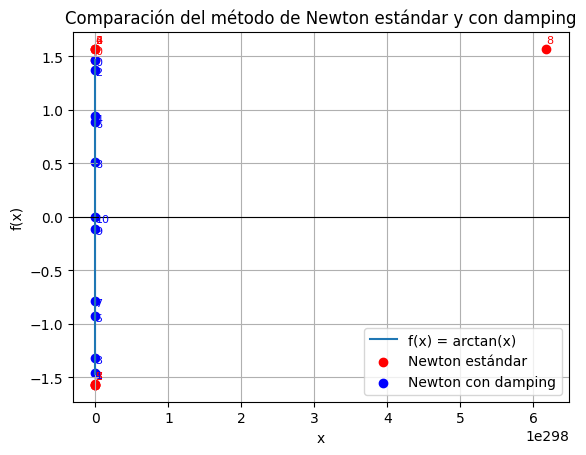

In [5]:
import matplotlib.pyplot as plt

f = lambda x: np.arctan(x)
df = lambda x: 1 / (1 + x**2)

def newton_standard(f, df, x0, tol=1e-6, max_iter=10):
    xs = [x0]
    x = x0
    for _ in range(max_iter):
        x_new = x - f(x)/df(x)
        xs.append(x_new)
        if abs(x_new - x) < tol:
            break
        x = x_new
    return np.array(xs)

def newton_damping(f, df, x0, tol=1e-6, max_iter=10, rho=0.5, c=1e-4):
    xs = [x0]
    x = x0
    for _ in range(max_iter):
        fx = f(x)
        dfx = df(x)
        p = -fx / dfx
        alpha = 1
        
        while abs(f(x + alpha*p)) > (1 - c*alpha)*abs(fx):
            alpha *= rho
        x_new = x + alpha*p
        xs.append(x_new)
        if abs(x_new - x) < tol:
            break
        x = x_new
    return np.array(xs)

x0 = 10
xs_std = newton_standard(f, df, x0)
xs_damp = newton_damping(f, df, x0)

x_vals = np.linspace(-10, 10, 400)
plt.plot(x_vals, f(x_vals), label='f(x) = arctan(x)')
plt.axhline(0, color='black', linewidth=0.8)

plt.scatter(xs_std, f(xs_std), color='red', label='Newton estándar')
plt.scatter(xs_damp, f(xs_damp), color='blue', label='Newton con damping')

for i, x in enumerate(xs_std):
    plt.text(x, f(x)+0.05, f"{i}", color='red', fontsize=8)

for i, x in enumerate(xs_damp):
    plt.text(x, f(x)-0.05, f"{i}", color='blue', fontsize=8)

plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Comparación del método de Newton estándar y con damping")
plt.legend()
plt.grid(True)
plt.show()


### 3. Análisis numérico

Al comparar los dos métodos con $f(x) = \arctan(x)$ y $x_0 = 10$, se nota una diferencia clara en la forma en que convergen.

Con el **método de Newton estándar**, el primer paso da un salto enorme porque $f'(x) = \frac{1}{1+x^2}$ es muy pequeño cuando $x$ es grande.  
Esto hace que $\frac{f(x)}{f'(x)}$ sea enorme y el método se vaya a valores lejanos o incluso tenga problemas numéricos. En este caso, el método se vuelve inestable y tarda más en acercarse a la raíz $x = 0$.

En cambio, el **método de Newton con damping** ajusta el tamaño del paso usando el factor $\alpha_k$ y la condición de Armijo.  
Esto evita esos saltos grandes, hace que el método avance con pasos más razonables y que la convergencia sea más estable, aunque un poco más lenta al principio.

En la gráfica se ve que los puntos del método estándar (en rojo) se alejan al inicio, mientras que los del método con damping (en azul) se mueven de forma más controlada hacia la raíz.

En resumen, el damping mejora la convergencia porque evita pasos demasiado grandes y mantiene el método estable incluso cuando se empieza lejos de la raíz.


# 4. Extensión:

In [6]:

# Sistema de ecuaciones
# F(x, y) = [x^2 + y^2 - 4, xy - 1]
def F(v):
    x, y = v
    return np.array([x**2 + y**2 - 4, x*y - 1])

def J(v):
    x, y = v
    return np.array([[2*x, 2*y],
                     [y, x]])

def newton_damping_2D(F, J, x0, tol=1e-6, max_iter=20, c=1e-4, beta=0.5):
    x = np.array(x0, dtype=float)
    print(f"{'Iter':>4} {'x':>10} {'y':>10} {'||F||':>12} {'alpha':>10}")
    print("-"*45)

    for k in range(max_iter):
        Fx = F(x)
        normF = np.linalg.norm(Fx)
        if normF < tol:
            break

        p = -np.linalg.solve(J(x), Fx)

        alpha = 1
        while np.linalg.norm(F(x + alpha*p)) > (1 - c*alpha)*normF:
            alpha *= beta
            if alpha < 1e-6:
                break

        x_new = x + alpha*p
        print(f"{k:4d} {x[0]:10.6f} {x[1]:10.6f} {normF:12.6f} {alpha:10.4f}")

        if np.linalg.norm(x_new - x) < tol:
            x = x_new
            break
        x = x_new

    print("\nAproximación final:", x)
    return x


In [7]:
x0 = [2, 1]
newton_damping_2D(F, J, x0)


Iter          x          y        ||F||      alpha
---------------------------------------------
   0   2.000000   1.000000     1.414214     1.0000
   1   2.000000   0.500000     0.250000     1.0000
   2   1.933333   0.516667     0.004851     1.0000
   3   1.931853   0.517637     0.000003     1.0000

Aproximación final: [1.93185165 0.51763809]


array([1.93185165, 0.51763809])

### 4. Extensión: Sistema en 2D

El sistema es:

$$
\begin{cases}
x^2 + y^2 = 4 \\
xy = 1
\end{cases}
$$

Para resolverlo con Newton, se usa la versión vectorial:

$
x_{k+1} = x_k - \alpha_k J(x_k)^{-1} F(x_k),
$
donde $J(x_k)$ es la matriz Jacobiana del sistema y $\alpha_k \in (0,1]$ se elige con backtracking.

En este caso:
$$
F(x, y) = 
\begin{pmatrix}
x^2 + y^2 - 4 \\
xy - 1
\end{pmatrix}, \quad
J(x, y) = 
\begin{pmatrix}
2x & 2y \\
y & x
\end{pmatrix}.
$$

La idea es igual que en 1D: se calcula la dirección de Newton $p = -J^{-1}F$ y luego se busca un $\alpha_k$ que reduzca el tamaño de $||F(x)||$ de forma suficiente según la condición de Armijo.

Si $\alpha_k = 1$ no mejora lo suficiente, se va reduciendo (por ejemplo $\alpha_k = 0.5, 0.25, 0.125, \dots$) hasta que el paso funcione bien.

En este sistema, el damping ayuda a que las iteraciones no se salgan del círculo $x^2 + y^2 = 4$, y se acerquen de forma más estable al punto donde se cumple también $xy = 1$.  
El método converge a una de las soluciones reales del sistema, alrededor de $(x, y) \approx (1.93, 0.52)$ o su simétrica $(0.52, 1.93)$.
